Here we'll demonstrate how to setup a power calculation for a simple A/B test with binary outcomes.  That is, our primary metric will be a conversion rate between 0.0 and 1.0 (or 0% and 100%).  We'll do this for:

1. A two variant test (i.e. one control group, and one treatment group)

2. A three variant test (i.e. one control group, and two distinct treatment groups)

There's nothing special about a three variant test, the conversion_rates_utils module in stats_utils can handle a power calculation for arbitrary numbers of variants.  

### Two variant A/B test power calculation example

1. We're trying to design an experiment with one treatment group and one control group

2. The primary metric is a conversion rate, meaning that outcomes for units in the experiment are binary (either a unit did an action, or they did not)

Our goal will be to investigate how long the experiment should run for, and what to expect in terms of a minimum detectable effect (MDE).  

Off the bat, there are a few things we'll need to know about our pre-experiment population:

1. We'll assume that, on average, we see ~10,000 eligible experimental units per day.  i.e. this is the number of units, per day, that could get assigned to either treatment or control.  

    a. In practice, this number might be quite variable (and even have seasonal effects).  
    
    b. It's important to understand when your experiment will run, and what kind of historical patterns to expect.  Knowning this ahead of time can help compute a reasonable time based average.  

2. We need to know what the baseline conversion rate is.  That is, before any intervention occurs, what conversion rate, on average, would we expect in our population?  We'll assume 5% here, but this will need to be calculated from historical data ahead of time.


3. We'll also need to set threshold for significant ($\alpha$) and power ($1 - \beta$).  For starters, we'll assume that we want to declare significance at the 95% threshold (i.e. $\alpha = 0.05$), and a power of at least 80% (i.e. $1 - \beta = 0.8$). These values are the current defaults in the code, but they are entirely customizable


In [1]:
import sys
import pandas as pd

In [2]:
# For now, this is a simple way to import the tools we need.
# Be sure to update the path to point to where the relevant code is stored on your machine
# TBD on eventually making this importable
sys.path.append('../../../ab_testing_utils/')

In [3]:
import conversion_rate_utils

In [4]:
# Based on our assumptions above:
daily_num_observations = 10000
baseline_conversion_rate = 0.05

In [5]:
# The conversion_rate_utils code for power analysis actually expects a parameter called monthly_num_obs.
# This is a poor naming choice, as it's actually the number of expected observations per 4 week period
# This will eventually get updated to work at daily grain, but for now,  given a daily expected number of observations, you can calculate it as:
monthly_num_observations = daily_num_observations * 7 * 4

The conversion_rate_utils module wraps up everything into one class: ConversionExperiment
This class gives you access to methods for both experimental design (i.e. power calcs), as well as analysis of results (which will demonstrate in a different notebook)

In [6]:
ab_test = conversion_rate_utils.ConversionExperiment()

In [7]:
# The first thing to do is create a minimum detectable effect size table. 
df_mde_ab = ab_test.create_mde_table(monthly_num_obs=monthly_num_observations, baseline_conversion_rate=baseline_conversion_rate)

In [8]:
# This contains a table of potential minimum detectable effect sizes, the sample size required for an experiment to detect this MDE (at the specified confidence and power), 
# and the number of days it would take to run the experiment. There's also a column which translates this into number of required weeks
df_mde_ab.head()

,mde,new_conversion_rate_upper_bound,new_conversion_rate_lower_bound,total_sample_size,sample_size_per_variant,days,weeks,weeks_non_rounded,fraction_of_expected_monthly_sample,monthly_additional_conversions_upper,monthly_additional_conversions_lower
0,0.001,0.05005,0.04995,596514860,298257430,59652,8522,8521.640857,2130.410214,14,-14
1,0.002,0.05010,0.04990,149128714,74564357,14913,2131,2130.410200,532.602550,28,-28
2,0.003,0.05015,0.04985,66279428,33139714,6628,947,946.848971,236.712243,42,-42
3,0.004,0.05020,0.04980,37282178,18641089,3729,533,532.602543,133.150636,56,-56
4,0.005,0.05025,0.04975,23860594,11930297,2387,341,340.865629,85.216407,70,-70


In principle this is all you need to make a call on experiment run time. There's likely a lot more information in here than we actually need.  In practice, we should never run an A/B test for less than 2 business cycles (i.e. 2 weeks). We also don't want to run an experiment for too long as that can be expensive, and can lead to questions about how comparable early data is to late data. 

To this end, we can use the make_mde_plot method to summarize this for us in a more digestable way, while truncating the results to potential experiment run times we'd realistically consider

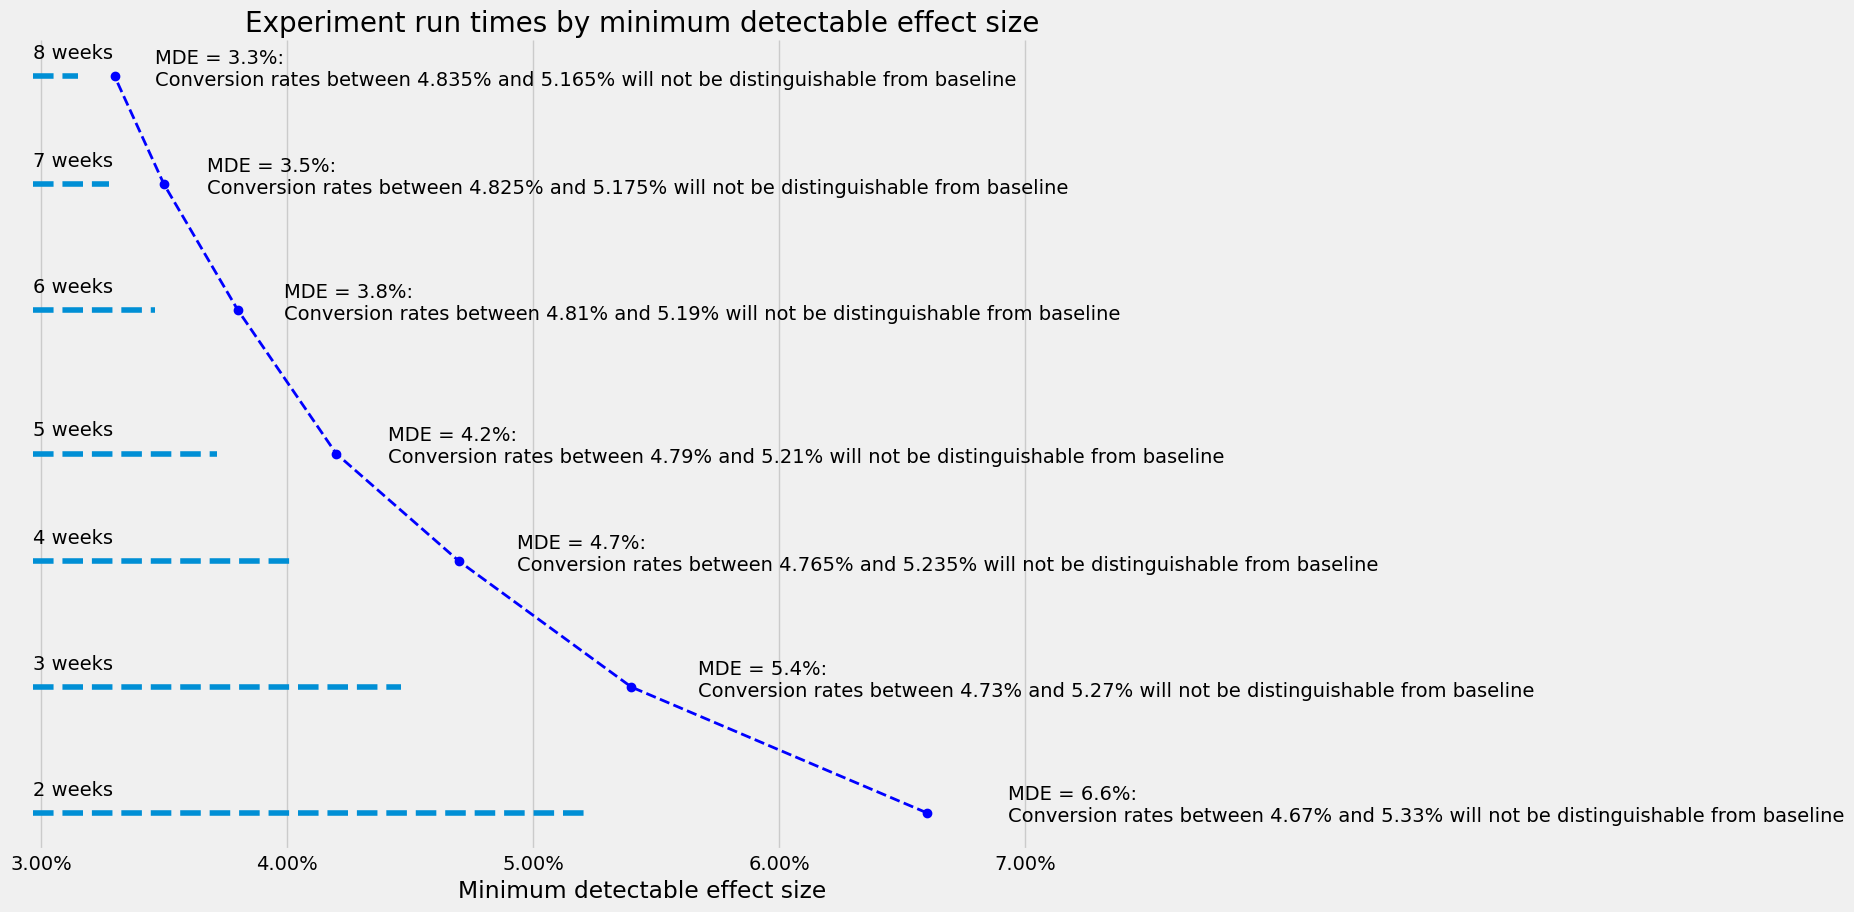

In [9]:
ab_test.make_mde_plot(df_=df_mde_ab, min_weeks=2, max_weeks=8, figsize=(14, 10))

The above summaizes our power calculations.  For example, this says that for an experiment powered at 80% and a significance threshold of 95%, we could run it for 4 weeks with the a required minimum detectable effect size of 4.7%. This means that our baseline conversion rate of 5% would need to increase to ((0.05)* (1 + 0.047) * 100%) = 5.235% in the treatment group, for the effect to be detectable. 

By default, the minimum detectable effect sizes in the plot above are selected for each runtime by selecting the MDE associated with the maximum number of days in a given number of weeks. 

For example, the MDE table for a 4 week runtime looks like this. 

In [10]:
df_mde_ab.query('weeks==4')

,mde,new_conversion_rate_upper_bound,new_conversion_rate_lower_bound,total_sample_size,sample_size_per_variant,days,weeks,weeks_non_rounded,fraction_of_expected_monthly_sample,monthly_additional_conversions_upper,monthly_additional_conversions_lower
46,0.047,0.05235,0.04765,270038,135019,28,4,3.857686,0.964421,658,-658
47,0.048,0.05240,0.04760,258904,129452,26,4,3.698629,0.924657,672,-672
48,0.049,0.05245,0.04755,248444,124222,25,4,3.549200,0.887300,686,-686
49,0.050,0.05250,0.04750,238606,119303,24,4,3.408657,0.852164,700,-700
50,0.051,0.05255,0.04745,229340,114670,23,4,3.276286,0.819071,714,-714
51,0.052,0.05260,0.04740,220604,110302,23,4,3.151486,0.787871,728,-728
52,0.053,0.05265,0.04735,212358,106179,22,4,3.033686,0.758421,742,-742


This happens because of the number of days that can fit into a week.  By default, the code will round up to the the nearest integer number of weeks. 

We can get the opposite MDE by specifying a parameters called "conservative_runtime" in the make_mde_plot method.  This will default to selecting the maximum minimum detectable effect size associated to each run time in weeks.  For example, for 4 weeks, this will select an MDE of 5.3% (i.e. the row associated with a 22 day run time).  It's recommended to do this if you think your estimate on the available sample size is highly variable. This will ensure that a conservative estimate is used for how large of an effect you'll need to measure 

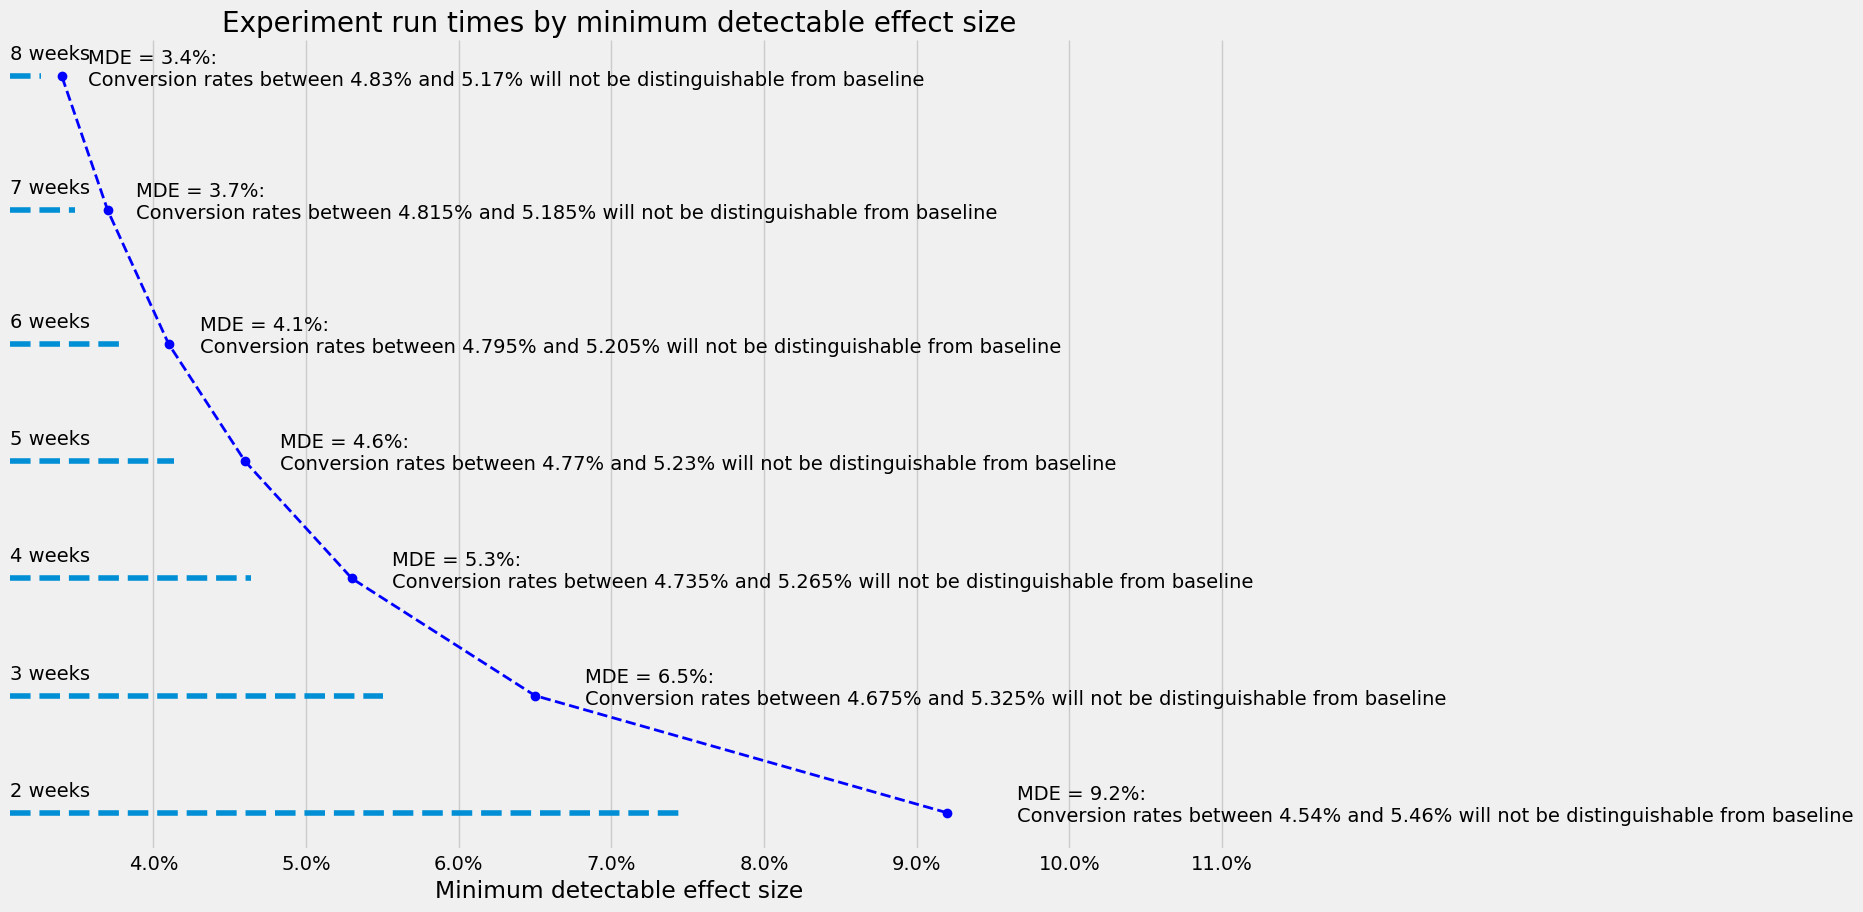

In [11]:
ab_test.make_mde_plot(df_=df_mde_ab, min_weeks=2, max_weeks=8, figsize=(14, 10), conservative_runtime=True)

We can also change the desired power and signficance level as well.  You can do this by generating a new MDE table and specifying the "alpha" and/or "power" arguments (the significance level of the test is 1 - alpha)

In [12]:
df_mde_ab_90_80 = ab_test.create_mde_table(monthly_num_obs=monthly_num_observations, baseline_conversion_rate=baseline_conversion_rate, alpha=0.1, power=0.7)

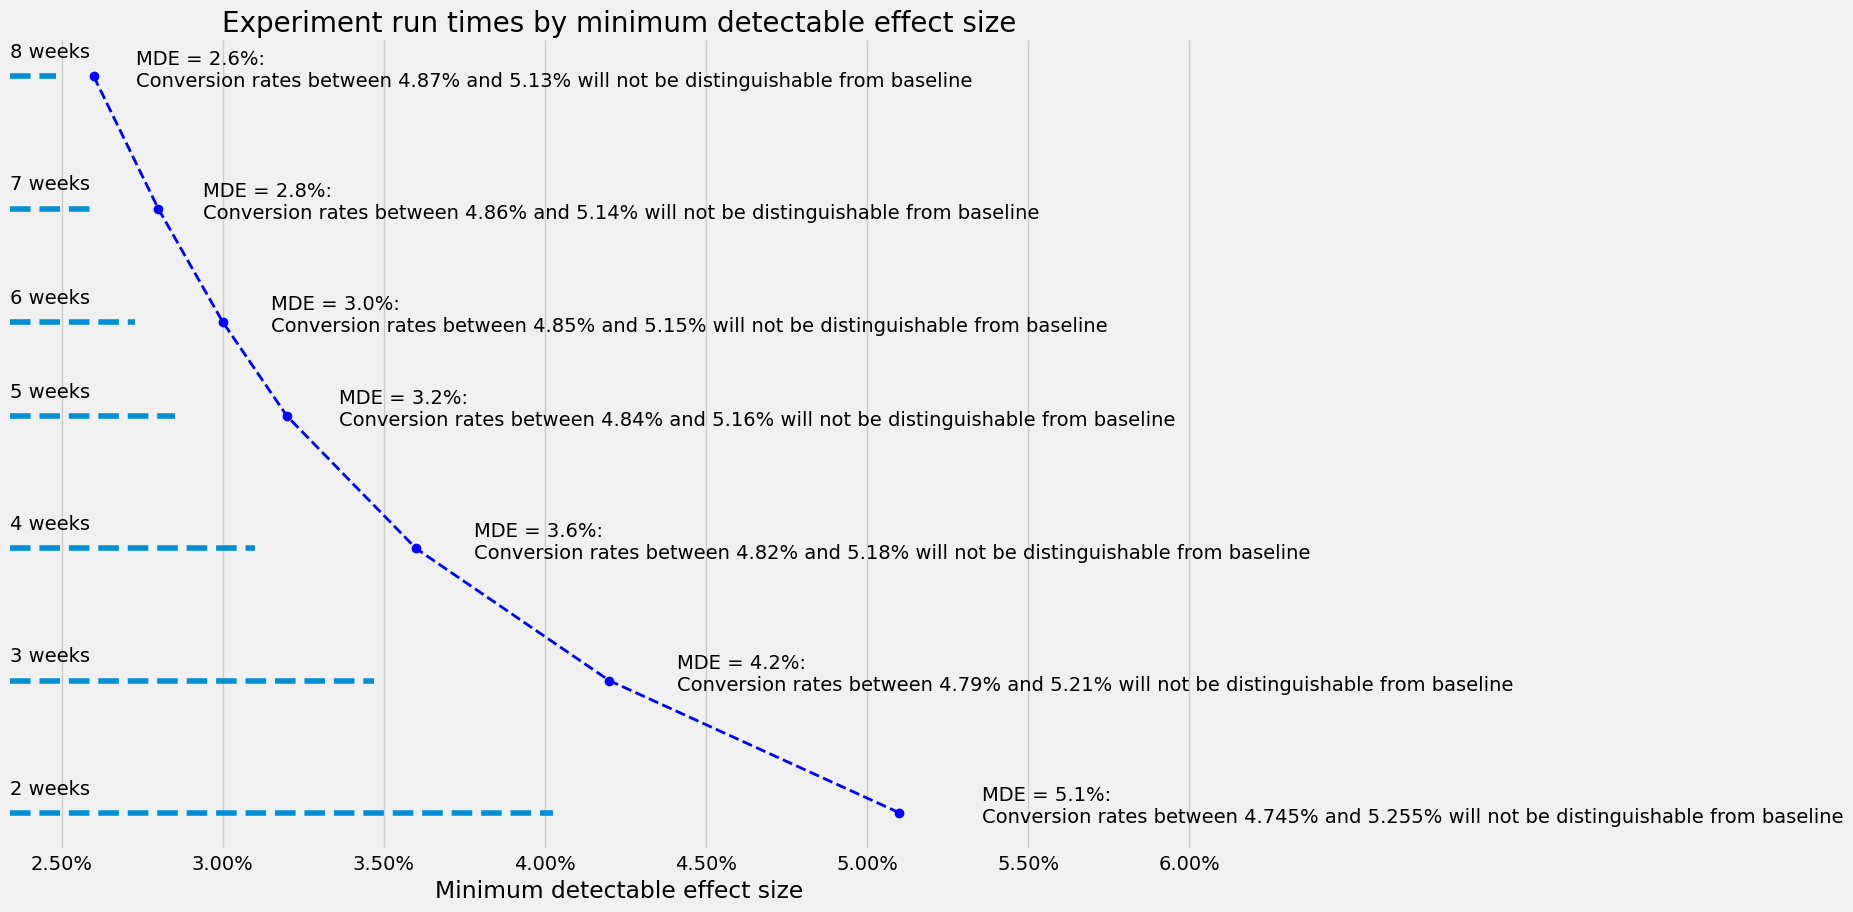

In [13]:
ab_test.make_mde_plot(df_=df_mde_ab_90_80, min_weeks=2, max_weeks=8, figsize=(14, 10))

Notice now the 4 week MDE is 3.6%. This is expected as we've relaxed the conditions on the level of significance and power required from the test

### Multi variant test

This is pretty much the same as the simple two variant test in the example above.  Here we'll assume:

1. The same number of expected daily eligible units (~10,000)

2. The same baseline conversion rate of 5%

3. This time though, we'll have two treatment variants 

Again, the goal will be to figure out an appropriate run time (in weeks) for the three variant test, at a specified power and level of significance

In [14]:
abc_test = conversion_rate_utils.ConversionExperiment()

In [15]:
df_mde_abc = abc_test.create_mde_table(monthly_num_obs=monthly_num_observations, baseline_conversion_rate=baseline_conversion_rate, n_variants=3)

In [16]:
df_mde_abc.head()

,mde,new_conversion_rate_upper_bound,new_conversion_rate_lower_bound,total_sample_size,sample_size_per_variant,days,weeks,weeks_non_rounded,fraction_of_expected_monthly_sample,monthly_additional_conversions_upper,monthly_additional_conversions_lower
0,0.001,0.05005,0.04995,894772290,298257430,89478,12783,12782.461286,3195.615321,14,-14
1,0.002,0.05010,0.04990,223693071,74564357,22370,3196,3195.615300,798.903825,28,-28
2,0.003,0.05015,0.04985,99419142,33139714,9942,1421,1420.273457,355.068364,42,-42
3,0.004,0.05020,0.04980,55923267,18641089,5593,799,798.903814,199.725954,56,-56
4,0.005,0.05025,0.04975,35790891,11930297,3580,512,511.298443,127.824611,70,-70


The MDE table looks the same as before. However, the run times now apply to the 3 variant test.  Notice that the required sample size is found in the column "total_sample_size". This is the total sample size (across all 3 variants) required for the experiment.  The column next to, "sample_size_per_variant", is the sample size required per variant. In other words, this is the sample size you'll need in the control group, and in each treatment group, respectively.  

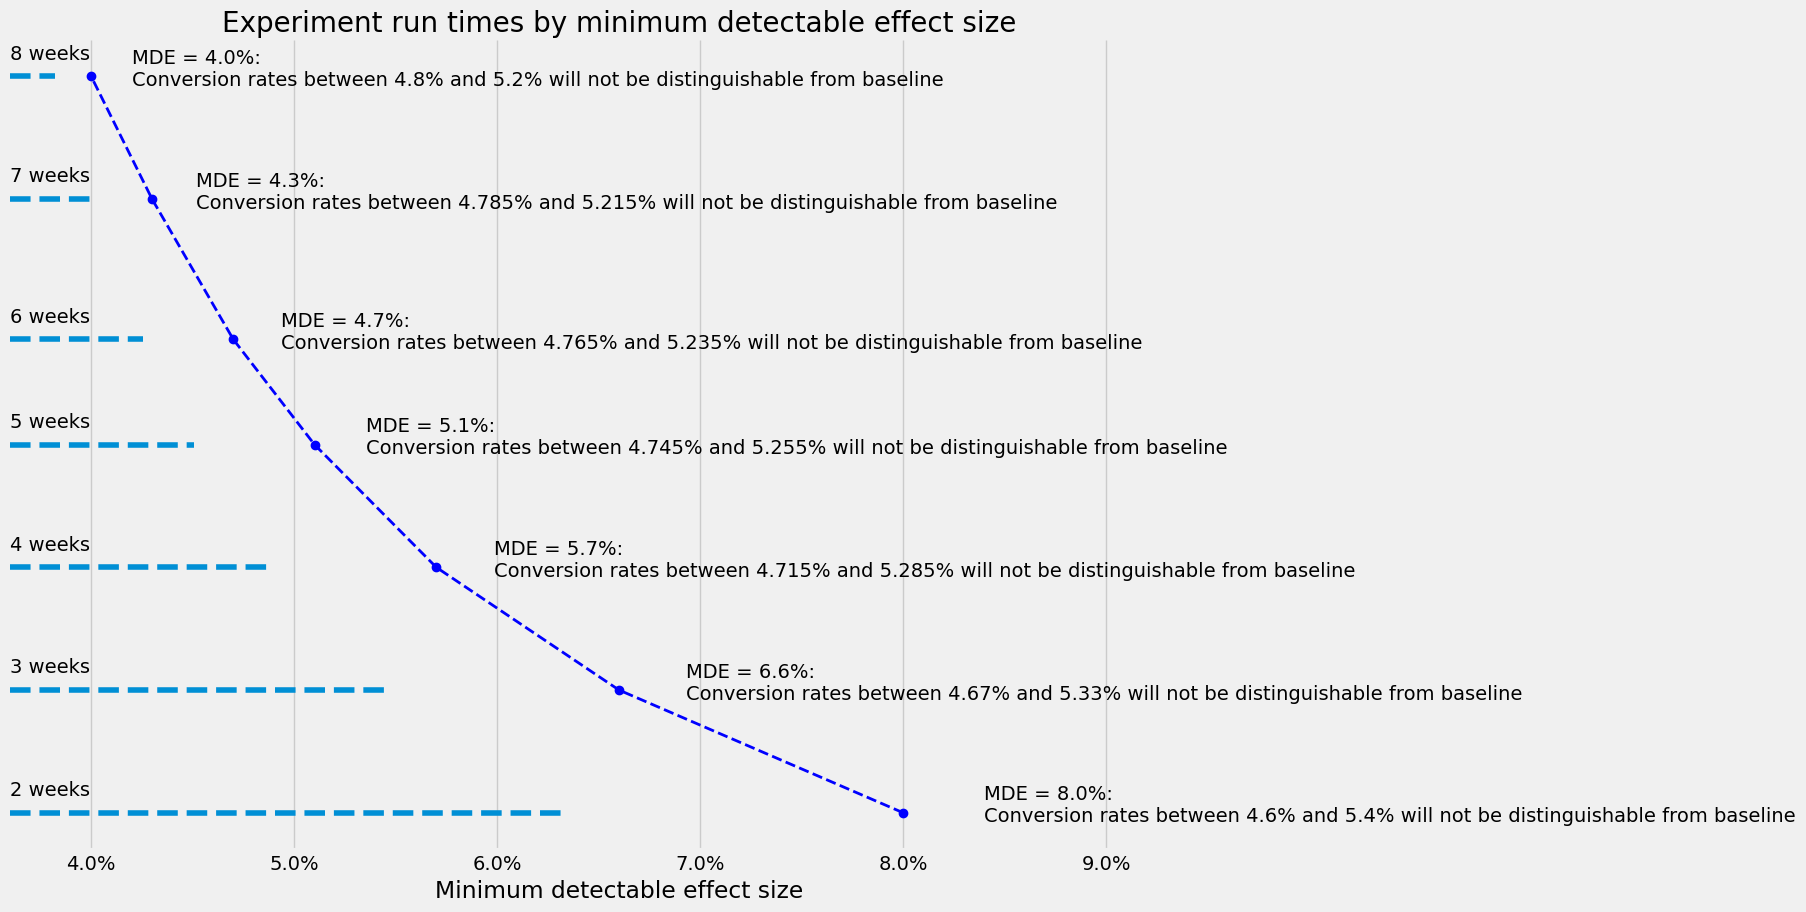

In [17]:
abc_test.make_mde_plot(df_=df_mde_abc, min_weeks=2, max_weeks=8, figsize=(14, 10))

This time around, you can see that a 4 week test has a higher required MDE (5.7%). This is expected given that we've introduced a new variant. This is the MDE that will be required for each treatment group to be distinguishable from the control, at the required power and signficance level (80% and 95%, respectively).  

### Appendix

How do the calculations actually work? TBD 